In [46]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [47]:
data =pd.read_csv("Books_Data_4_EDA.csv")

In [48]:

data.tail()

# data=['language_code']
# data['']

,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
1065,1065,2014.0,Gray Mountain,John Grisham,eng,Intermediate,3.52,37379,nonfiction,104.94,62.964,0.99,1268,"Amazon Digital Services, Inc.",106
1066,1066,1989.0,The Power of One,Bryce Courtenay,eng,Excellent,4.34,57312,genre fiction,846.94,508.164,7.99,1270,Random House LLC,106
1067,1067,1930.0,The Maltese Falcon,Dashiell Hammett,eng,Intermediate,3.92,58742,genre fiction,846.94,508.164,7.99,1271,Hachette Book Group,106
1068,1068,2011.0,Night Road,Kristin Hannah,en-US,Excellent,4.17,58028,genre fiction,104.94,62.964,0.99,1272,"Amazon Digital Services, Inc.",106
1069,1069,1999.0,Tripwire,Lee Child,eng,Excellent,4.07,55251,genre fiction,316.94,0.000,2.99,1273,"Amazon Digital Services, Inc.",106


In [49]:
# data['language_code'].str.split('-')[0]
# data['language_code']=data['language_code'].str.replace("US","")

In [50]:
# data['language_code']=data['language_code'].str.replace("-","")

In [51]:
# list(data['language_code'])

In [52]:
# for i in range(len(data)):
#     data.loc[i, "language_code"] = "eng"

In [53]:
# data["language_code"].unique()

In [54]:
data['Publishing Year'] = data['Publishing Year'].astype('Int64')

In [55]:
data['Publishing Year'] = data['Publishing Year'].astype('Int64').astype(str)
data['Publishing Year'] = data['Publishing Year'].astype(str).str.replace('.0', '', regex=False)
data['Publishing Year']

0       1975
1       1987
2       2015
3       2008
4       2011
        ... 
1065    2014
1066    1989
1067    1930
1068    2011
1069    1999
Name: Publishing Year, Length: 1070, dtype: str

In [56]:
data.isna().sum()
data['Book Name']=data['Book Name'].fillna("not_name",inplace=True)
# data['Publishing Year']=data['Publishing Year'].fillna(000,inplace=True)


C:\Users\dell\AppData\Local\Temp\ipykernel_7276\1475756179.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  data['Book Name']=data['Book Name'].fillna("not_name",inplace=True)


In [57]:
data.isna().sum()

index                   0
Publishing Year         1
Book Name               0
Author                  0
language_code          53
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64

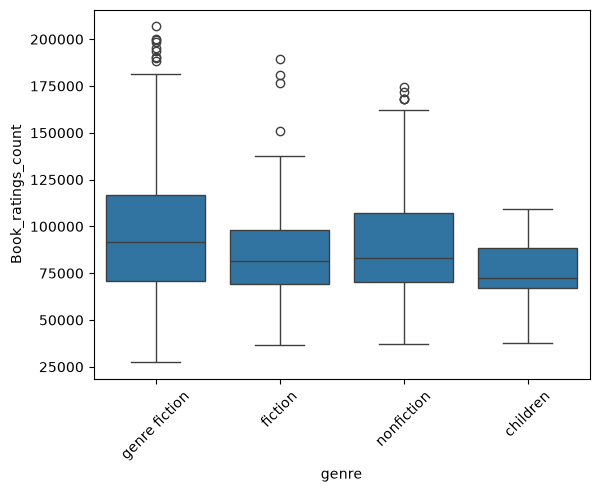

In [58]:
top_genres = data["genre"].value_counts().head(10).index

sns.boxplot(
    x="genre",
    y="Book_ratings_count",
    data=data[data["genre"].isin(top_genres)]
)

plt.xticks(rotation=45)
plt.show()

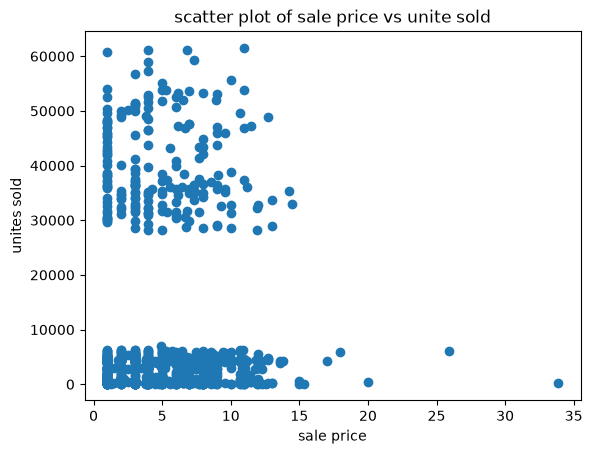

In [59]:
plt.scatter(data['sale price'], data['units sold'])
plt.xlabel("sale price")
plt.ylabel("unites sold")
plt.title("scatter plot of sale price vs unite sold")
plt.show()

In [60]:
language_code = data['language_code'].value_counts()

ValueError: unsupported format character '.' (0x2e) at index 3

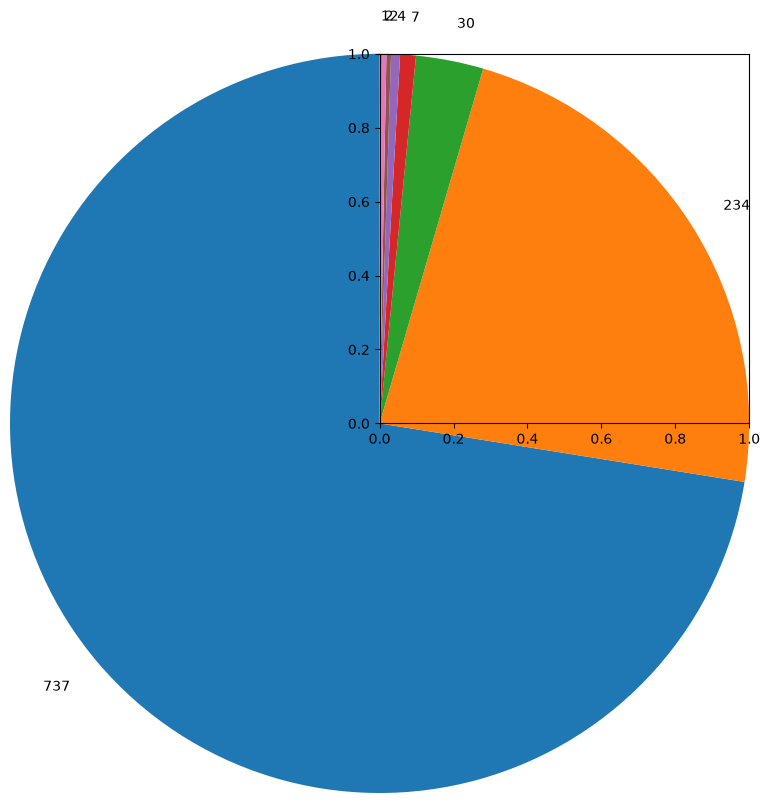

In [61]:
plt.pie(language_code,labels=language_code, startangle=90,autopct = "%1..1f%%")
plt.title("language code")
plt.show()

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   str    
 2   Book Name            1070 non-null   str    
 3   Author               1070 non-null   str    
 4   language_code        1070 non-null   str    
 5   Author_Rating        1070 non-null   str    
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   str    
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   str    
 14  units sold           1070 non-null   int64  
dtypes: float64(4), int64(4), str(7)
memory usage: 227

data.groupby("Publisher")["publisher revenue"].sum()

In [ ]:
data.groupby("Author_Rating")['Book_ratings_count'].mean().sort_values(ascending=False)

Author_Rating
Intermediate    101946.995200
Famous           97414.301887
Novice           88728.166667
Excellent        82905.889503
Name: Book_ratings_count, dtype: float64

In [62]:
data.groupby("language_code").size().sort_values(ascending=False)

language_code
eng      737
en-US    234
en-GB     30
en-CA      7
fre        4
ara        2
spa        2
nl         1
dtype: int64

In [64]:
data.columns

Index(['index', 'Publishing Year', 'Book Name', 'Author', 'language_code',
       'Author_Rating', 'Book_average_rating', 'Book_ratings_count', 'genre',
       'gross sales', 'publisher revenue', 'sale price', 'sales rank',
       'Publisher ', 'units sold'],
      dtype='str')

<Axes: xlabel='Author_Rating'>

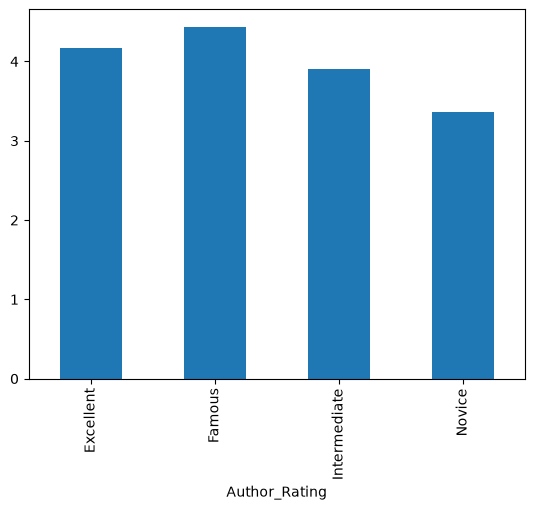

In [67]:
data.groupby("Author_Rating")['Book_average_rating'].mean().plot(kind='bar')

<Axes: >

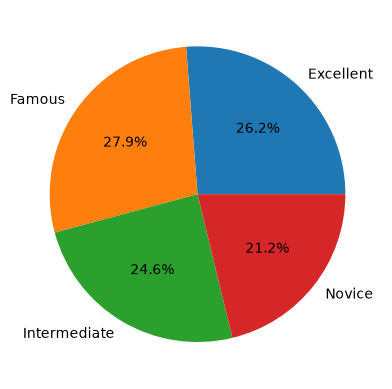

In [69]:
data.groupby("Author_Rating")['Book_average_rating'].mean().plot(kind='pie',autopct="%1.1f%%")

In [70]:
total_grogg = data.groupby("Author")['gross sales'].sum()

([0, 1, 2, 3],
 [Text(0, 0, 'Novice'),
  Text(1, 0, 'Intermediate'),
  Text(2, 0, 'Famous'),
  Text(3, 0, 'Excellent')])

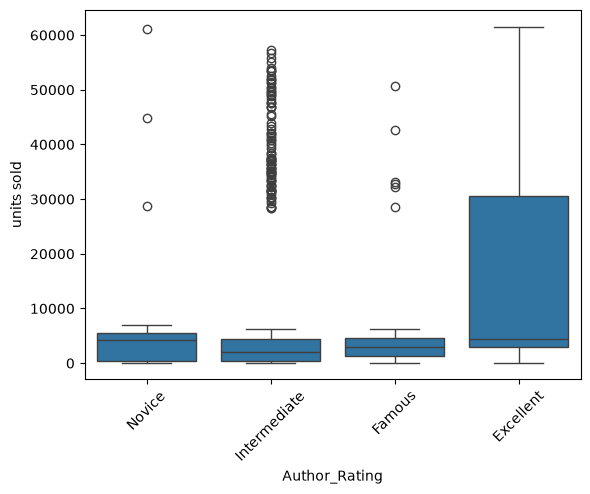

In [73]:
sns.boxplot(x = "Author_Rating",y="units sold", data=data)
plt.xticks(rotation=45)